In [ ]:
# ============================================================
# GM(1,1) MODIFICADO MEDIANTE SERIES DE FOURIER
# Corrección de los residuos del error
# Ecuaciones (22) - (30)
# Series: Sensor, Estación y Sensor corregido (desde Excel)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files


# ============================================================
# 1. SUBIR Y LEER EL EXCEL
# ============================================================

subido = files.upload()
nombre_archivo = list(subido.keys())[0]
df = pd.read_excel(nombre_archivo)
print(df.columns.tolist())

col_fecha     = "Fecha"
col_sensor    = "Sensor"
col_ref       = "Estacion"
col_corregido = "Sensor_corregido"

Saving regresion_lineal_simple_datos_corregidos.xlsx to regresion_lineal_simple_datos_corregidos.xlsx
['Fecha', 'Estacion', 'Sensor', 'Sensor_corregido']



Datos útiles: 15 filas

SERIE: Sensor (sin corregir)
a = -0.0082541916
b = 61.7824916492
T = 14
z = 6  ->  13 coeficientes para 14 residuos

Predicción GM(1,1):
[66.         62.58520811 63.10393631 63.6269639  64.15432654 64.68606014
 65.22220093 65.76278545 66.30785053 66.85743329 67.41157119 67.97030198
 68.53366372 69.10169481 69.67443394]

Residuos originales:
[ 1.41479189 -0.10393631  1.3730361  -5.15432654 -3.68606014  2.77779907
  3.23721455 -0.30785053  1.14256671  0.58842881  0.02969802  0.46633628
 -0.10169481 -1.67443394]

Residuos estimados por Fourier:
[ 0.92782507  0.38303051  0.88606928 -4.66735972 -4.17302696  3.26476589
  2.75024773  0.17911629  0.65559989  1.07539563 -0.4572688   0.95330309
 -0.58866163 -1.18746712]

GM(1,1) corregido por Fourier:
[66.         63.51303318 63.48696682 64.51303318 59.48696682 60.51303318
 68.48696682 68.51303318 66.48696682 67.51303318 68.48696682 67.51303318
 69.48696682 68.51303318 68.48696682]

--- COMPARACIÓN DE ERRORES ---
ARPE GM

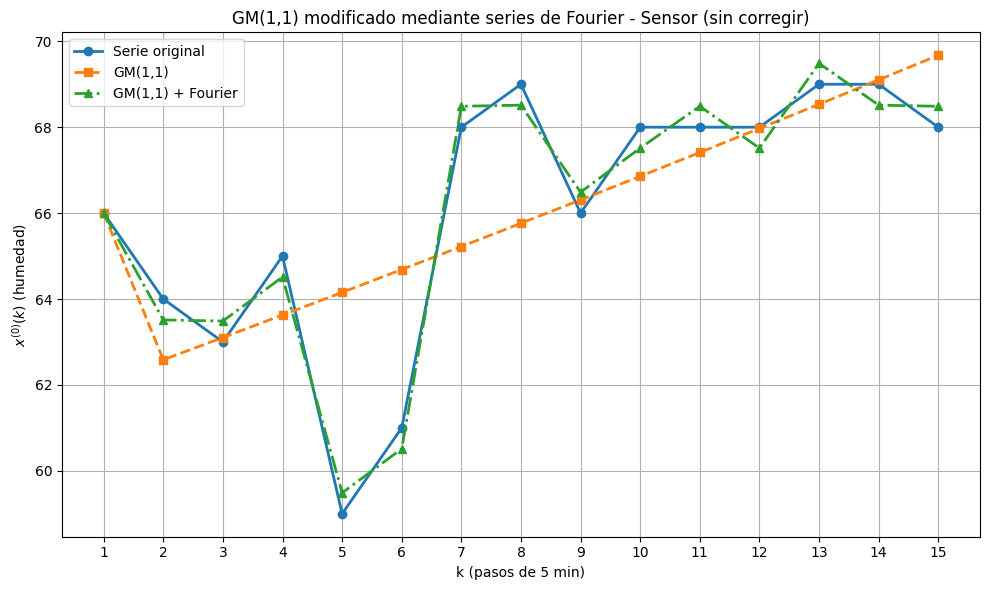

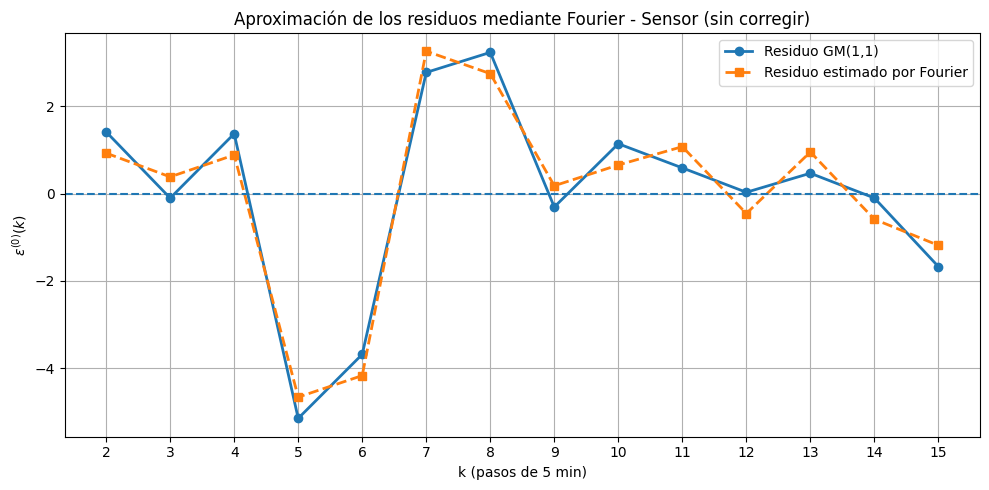

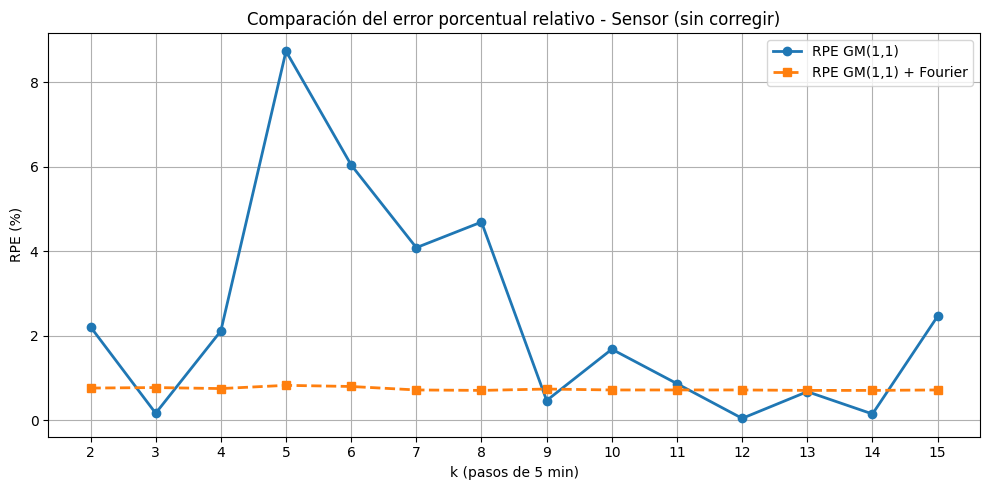


SERIE: Estación
a = -0.0070239369
b = 72.9801933563
T = 14
z = 6  ->  13 coeficientes para 14 residuos

Predicción GM(1,1):
[73.2        73.75306074 74.27292118 74.79644595 75.32366086 75.85459193
 76.38926536 76.92770752 77.46994497 78.01600448 78.56591297 79.11969758
 79.67738564 80.23900465 80.80458232]

Residuos originales:
[-0.15306074 -1.17292118 -2.29644595 -2.52366086 -0.85459193  2.31073464
  3.57229248  2.33005503  1.98399552  1.93408703  0.38030242 -0.87738564
 -2.33900465 -2.30458232]

Residuos estimados por Fourier:
[-0.19571506 -1.13026686 -2.33910026 -2.48100654 -0.89724625  2.35338896
  3.52963817  2.37270935  1.9413412   1.97674135  0.3376481  -0.83473132
 -2.38165897 -2.261928  ]

GM(1,1) corregido por Fourier:
[73.2        73.55734568 73.14265432 72.45734568 72.84265432 74.95734568
 78.74265432 80.45734568 79.84265432 79.95734568 80.54265432 79.45734568
 78.84265432 77.85734568 78.54265432]

--- COMPARACIÓN DE ERRORES ---
ARPE GM(1,1)          = 2.306600 %
ARPE GM(1

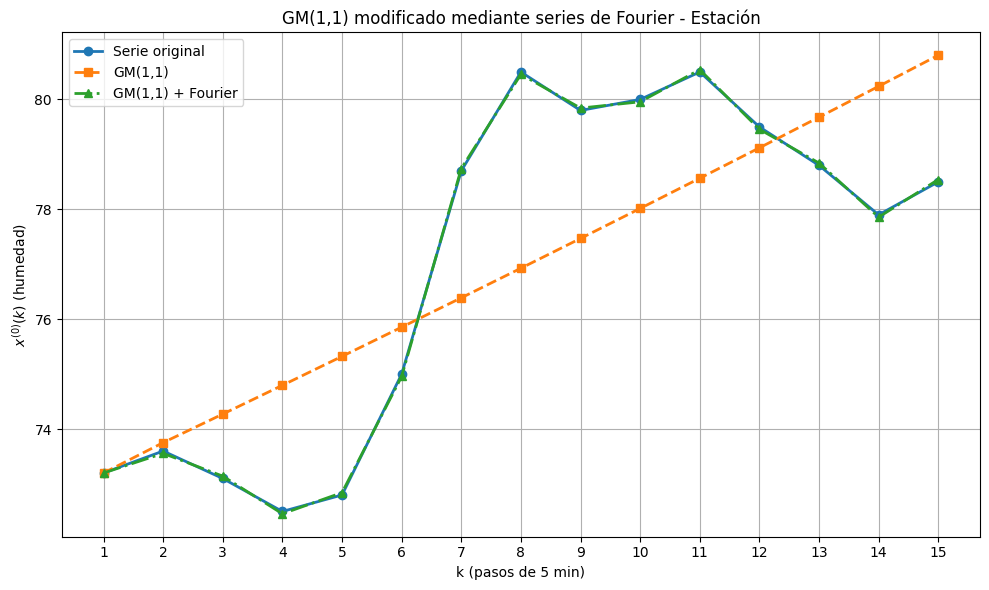

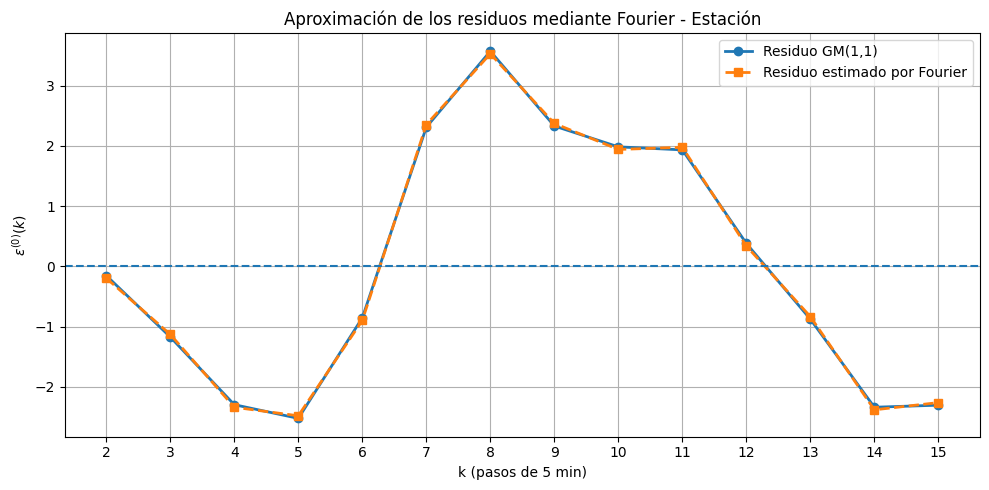

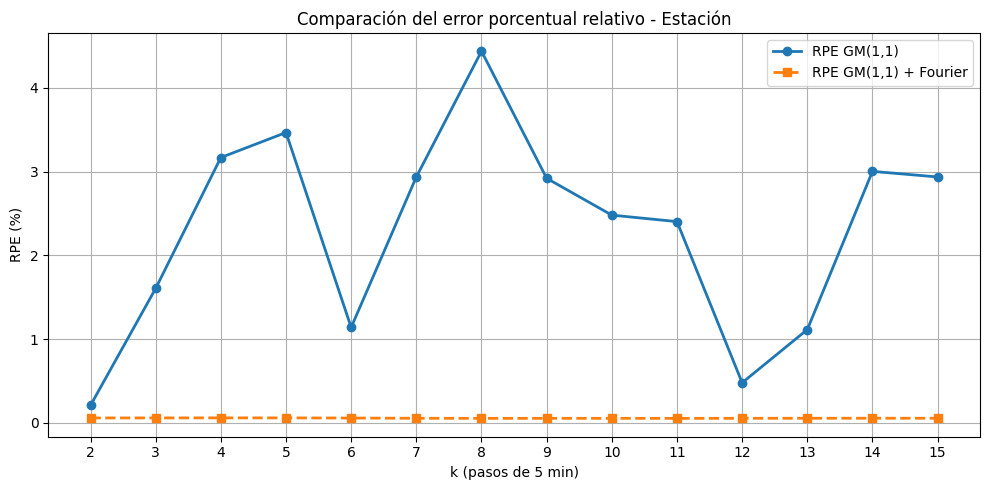


SERIE: Sensor corregido
a = -0.0046372216
b = 71.9823829119
T = 14
z = 6  ->  13 coeficientes para 14 residuos

Predicción GM(1,1):
[74.68295069 72.49666594 72.83362973 73.17215973 73.51226321 73.85394748
 74.1972199  74.54208785 74.88855874 75.23664002 75.58633919 75.93766375
 76.29062126 76.64521932 77.00146554]

Residuos originales:
[ 0.91751147 -0.05383896  0.87640432 -3.27001899 -2.34292999  1.75450406
  2.04402275 -0.20560806  0.71508394  0.36538477  0.01406021  0.29548934
 -0.05910872 -1.04974158]

Residuos estimados por Fourier:
[ 0.60830622  0.25536628  0.56719908 -2.96081374 -2.65213523  2.0637093
  1.73481751  0.10359719  0.40587869  0.67459002 -0.29514503  0.60469458
 -0.36831396 -0.74053634]

GM(1,1) corregido por Fourier:
[74.68295069 73.10497217 73.08899601 73.7393588  70.55144946 71.20181225
 76.2609292  76.27690536 74.99215593 75.64251872 76.2609292  75.64251872
 76.89531584 76.27690536 76.2609292 ]

--- COMPARACIÓN DE ERRORES ---
ARPE GM(1,1)          = 1.355674 %
AR

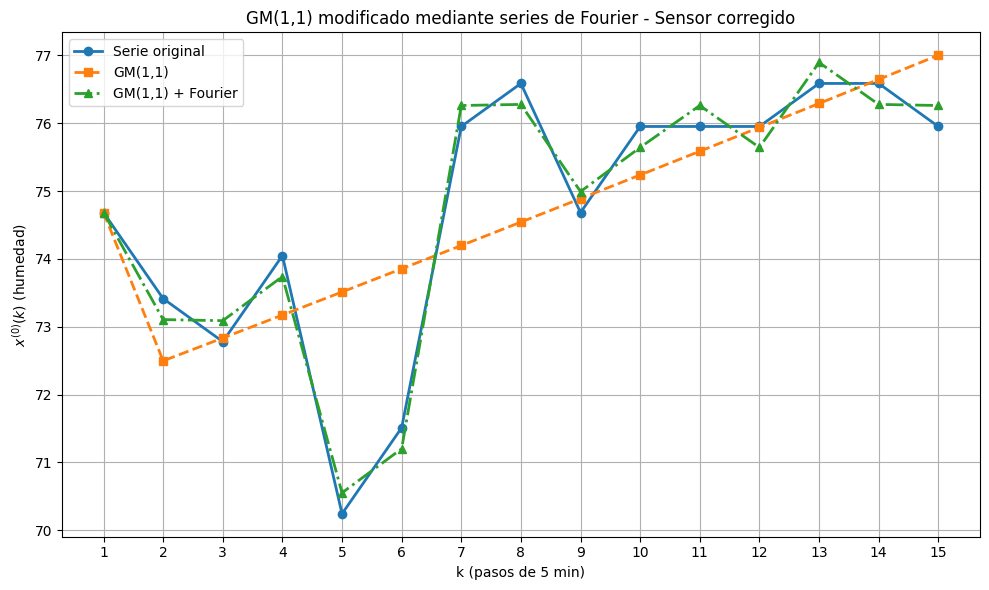

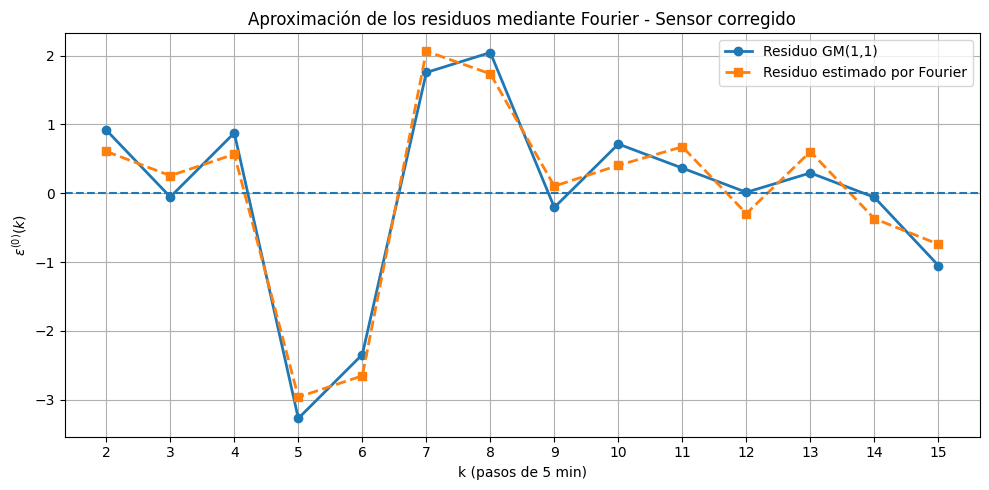

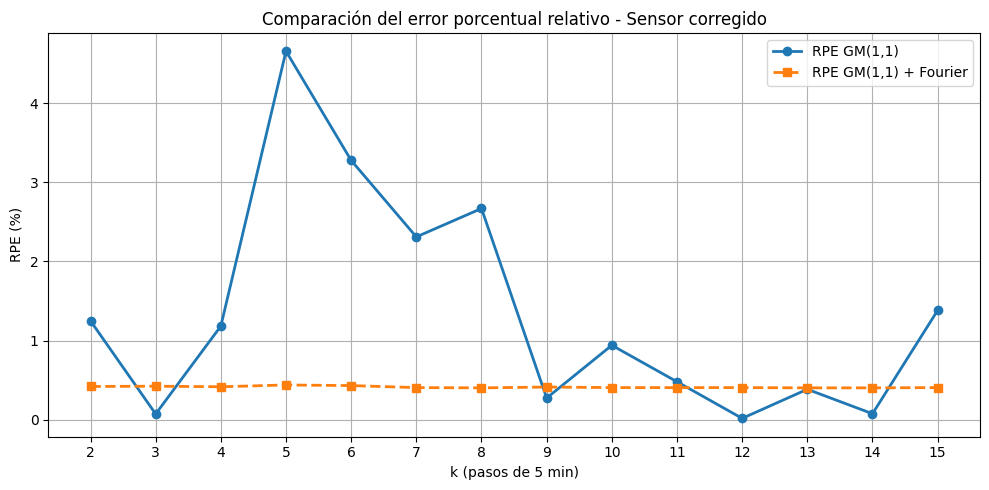


RESUMEN ARPE POR SERIE
Sensor (sin corregir):
   GM(1,1)         = 2.456055 %
   GM(1,1)+Fourier = 0.738744 %
Estación:
   GM(1,1)         = 2.306600 %
   GM(1,1)+Fourier = 0.055316 %
Sensor corregido:
   GM(1,1)         = 1.355674 %
   GM(1,1)+Fourier = 0.414068 %


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


n = 15                  # filas a usar; None = todas (ver nota sobre sobreajuste)
mostrar_detalle = False # True = imprime serie acumulada, Z1, matriz P, etc.


# ============================================================
# 2. LIMPIEZA Y SERIES ORIGINALES X^(0)
# ============================================================

datos = df[[col_fecha, col_ref, col_sensor, col_corregido]].copy()
datos[col_fecha] = pd.to_datetime(datos[col_fecha], errors="coerce")
for c in [col_ref, col_sensor, col_corregido]:
    datos[c] = pd.to_numeric(datos[c], errors="coerce")
datos = datos.dropna().sort_values(col_fecha).reset_index(drop=True)

if n:
    datos = datos.head(n)

series = {
    "Sensor (sin corregir)": datos[col_sensor].to_numpy(dtype=float),
    "Estación":              datos[col_ref].to_numpy(dtype=float),
    "Sensor corregido":      datos[col_corregido].to_numpy(dtype=float),
}

print(f"\nDatos útiles: {len(datos)} filas")


# ============================================================
# 3. GM(1,1) + FOURIER PARA CADA SERIE
# ============================================================

resultados_fourier = {}

for nombre, X0 in series.items():

    print("\n" + "=" * 60)
    print(f"SERIE: {nombre}")
    print("=" * 60)

    N = len(X0)      # tamaño de la serie (se llama N para no pisar `n`)

    # --------------------------------------------------------
    # AGO:  X^(1)(k) = sum X^(0)(i)
    # --------------------------------------------------------
    X1 = np.cumsum(X0)

    # --------------------------------------------------------
    # SECUENCIA DE VALORES MEDIOS Z^(1)
    # z^(1)(k) = 0.5*x^(1)(k) + 0.5*x^(1)(k-1)
    # --------------------------------------------------------
    Z1 = 0.5 * (X1[1:] + X1[:-1])

    # --------------------------------------------------------
    # B Y Y
    # --------------------------------------------------------
    B = np.column_stack((-Z1, np.ones(N - 1)))
    Y = X0[1:].reshape(-1, 1)

    # --------------------------------------------------------
    # ESTIMAR a Y b
    # --------------------------------------------------------
    parametros = np.linalg.lstsq(B, Y, rcond=None)[0]
    a = parametros[0, 0]
    b = parametros[1, 0]

    print(f"a = {a:.10f}")
    print(f"b = {b:.10f}")

    if abs(a) < 1e-12:
        print("AVISO: a ≈ 0, la fórmula divide entre cero. Se omite esta serie.")
        continue

    # --------------------------------------------------------
    # PREDICCIÓN GM(1,1) - Ecuación (22)
    # x_p^(0)(k+1) = [x^(0)(1)-b/a] exp(-ak)(1-exp(a))
    # --------------------------------------------------------
    k_modelo = np.arange(1, N)

    X0_pred_restante = (
        (X0[0] - b/a)
        * np.exp(-a * k_modelo)
        * (1 - np.exp(a))
    )

    # Primer dato = condición inicial
    X0_pred = np.concatenate(([X0[0]], X0_pred_restante))

    # --------------------------------------------------------
    # RESIDUOS - Ecuaciones (23) y (24)
    # epsilon(k) = x(k) - xp(k),  k = 2,...,N
    # --------------------------------------------------------
    epsilon = X0[1:] - X0_pred[1:]

    # --------------------------------------------------------
    # PARÁMETROS DE FOURIER - Ecuación (25)
    # T = N - 1
    # z = ((N - 1)/2) - 1   (entero)
    # --------------------------------------------------------
    T = N - 1
    z = max(0, int((N - 1) / 2 - 1))

    print(f"T = {T}")
    print(f"z = {z}  ->  {1 + 2*z} coeficientes para {N - 1} residuos")

    # --------------------------------------------------------
    # MATRIZ P:  epsilon ≈ P C
    # C = [a0, a1, b1, a2, b2, ...]^T
    # --------------------------------------------------------
    k_fourier = np.arange(2, N + 1)

    columnas_P = [0.5 * np.ones(len(k_fourier))]

    for i in range(1, z + 1):
        columnas_P.append(np.cos(2 * np.pi * i * k_fourier / T))
        columnas_P.append(np.sin(2 * np.pi * i * k_fourier / T))

    P = np.column_stack(columnas_P)

    # --------------------------------------------------------
    # COEFICIENTES DE FOURIER - Ecuación (29)
    # C ≈ (P^T P)^(-1) P^T epsilon   (con lstsq por estabilidad)
    # --------------------------------------------------------
    C = np.linalg.lstsq(P, epsilon, rcond=None)[0]

    # --------------------------------------------------------
    # RESIDUOS ESTIMADOS POR FOURIER:  epsilon_hat = P C
    # --------------------------------------------------------
    epsilon_fourier = P @ C

    # --------------------------------------------------------
    # CORRECCIÓN DEL GM(1,1)
    # X_corregido = X_pred + epsilon_fourier
    # --------------------------------------------------------
    X0_fourier = X0_pred.copy()
    X0_fourier[1:] = X0_pred[1:] + epsilon_fourier

    # --------------------------------------------------------
    # ERRORES: GM(1,1) ORIGINAL Y GM(1,1)+FOURIER
    # --------------------------------------------------------
    error_GM = X0[1:] - X0_pred[1:]
    RPE_GM = np.abs(error_GM) / np.abs(X0[1:]) * 100
    ARPE_GM = np.mean(RPE_GM)

    error_Fourier = X0[1:] - X0_fourier[1:]
    RPE_Fourier = np.abs(error_Fourier) / np.abs(X0[1:]) * 100
    ARPE_Fourier = np.mean(RPE_Fourier)

    # --------------------------------------------------------
    # GUARDAR RESULTADOS
    # --------------------------------------------------------
    resultados_fourier[nombre] = {
        "a": a, "b": b,
        "X0_pred": X0_pred,
        "epsilon": epsilon,
        "epsilon_fourier": epsilon_fourier,
        "C": C,
        "X0_fourier": X0_fourier,
        "RPE_GM": RPE_GM,
        "RPE_Fourier": RPE_Fourier,
        "ARPE_GM": ARPE_GM,
        "ARPE_Fourier": ARPE_Fourier,
    }

    # --------------------------------------------------------
    # MOSTRAR RESULTADOS
    # --------------------------------------------------------
    if mostrar_detalle:
        print("\nSerie original X^(0):")
        print(X0)
        print("\nSerie acumulada X^(1):")
        print(X1)
        print("\nSecuencia Z^(1):")
        print(Z1)
        print("\nMatriz P:")
        print(P)
        print("\nCoeficientes de Fourier:")
        print(C)

    print("\nPredicción GM(1,1):")
    print(X0_pred)

    print("\nResiduos originales:")
    print(epsilon)

    print("\nResiduos estimados por Fourier:")
    print(epsilon_fourier)

    print("\nGM(1,1) corregido por Fourier:")
    print(X0_fourier)

    print("\n--- COMPARACIÓN DE ERRORES ---")
    print(f"ARPE GM(1,1)          = {ARPE_GM:.6f} %")
    print(f"ARPE GM(1,1)+Fourier  = {ARPE_Fourier:.6f} %")

    # --------------------------------------------------------
    # TABLA COMPARATIVA
    # --------------------------------------------------------
    k = np.arange(1, N + 1)

    tabla = pd.DataFrame({
        'k': k,
        'X original': X0,
        'GM(1,1)': X0_pred,
        'GM(1,1)+Fourier': X0_fourier
    })

    print("\nTABLA COMPARATIVA")
    print(tabla.to_string(index=False))

    # --------------------------------------------------------
    # GRÁFICA COMPARATIVA
    # --------------------------------------------------------
    plt.figure(figsize=(10, 6))

    plt.plot(k, X0, marker='o', linewidth=2, label='Serie original')
    plt.plot(k, X0_pred, marker='s', linestyle='--', linewidth=2, label='GM(1,1)')
    plt.plot(k, X0_fourier, marker='^', linestyle='-.', linewidth=2,
             label='GM(1,1) + Fourier')

    plt.xlabel('k (pasos de 5 min)')
    plt.ylabel(r'$x^{(0)}(k)$ (humedad)')
    plt.title(f'GM(1,1) modificado mediante series de Fourier - {nombre}')

    plt.xticks(k)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # GRÁFICA DE LOS RESIDUOS
    # --------------------------------------------------------
    plt.figure(figsize=(10, 5))

    plt.plot(k[1:], epsilon, marker='o', linewidth=2, label='Residuo GM(1,1)')
    plt.plot(k[1:], epsilon_fourier, marker='s', linestyle='--', linewidth=2,
             label='Residuo estimado por Fourier')
    plt.axhline(y=0, linestyle='--')

    plt.xlabel('k (pasos de 5 min)')
    plt.ylabel(r'$\varepsilon^{(0)}(k)$')
    plt.title(f'Aproximación de los residuos mediante Fourier - {nombre}')

    plt.xticks(k[1:])
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # GRÁFICA RPE
    # --------------------------------------------------------
    plt.figure(figsize=(10, 5))

    plt.plot(k[1:], RPE_GM, marker='o', linewidth=2, label='RPE GM(1,1)')
    plt.plot(k[1:], RPE_Fourier, marker='s', linestyle='--', linewidth=2,
             label='RPE GM(1,1) + Fourier')

    plt.xlabel('k (pasos de 5 min)')
    plt.ylabel('RPE (%)')
    plt.title(f'Comparación del error porcentual relativo - {nombre}')

    plt.xticks(k[1:])
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# 4. RESUMEN ARPE POR SERIE
# ============================================================

print("\n" + "=" * 60)
print("RESUMEN ARPE POR SERIE")
print("=" * 60)
for nombre, r in resultados_fourier.items():
    print(f"{nombre}:")
    print(f"   GM(1,1)         = {r['ARPE_GM']:.6f} %")
    print(f"   GM(1,1)+Fourier = {r['ARPE_Fourier']:.6f} %")